# Обзор датасетов: ETTm1, Weather и Electricity

Исследуем локальные данные из `configs/benchmark.yaml` одинаковыми методами.
Все доступные NPY описываются в инвентаризации, но статистики рассчитываются на **train**,
а изменения распределений и простые прогнозы проверяются на **validation**.
**Test по умолчанию не исследуется**; его размер показан только как часть протокола.

NPY не содержит временных меток и названий датчиков. Частота и сезонный период взяты из
конфигурации; регулярность времени по самому NPY подтвердить нельзя. Нумерация каналов
сохранена без предположений о физических величинах. ETTm1 обрезается до 57 600 строк,
как в экспериментах, хотя исходный файл длиннее. GPU и веса моделей не нужны.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/tshybrid").is_dir() and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из time-series-hybrid или его notebooks.")
sys.path.insert(0, str(ROOT / "src"))
from tshybrid.exploration import (
    load_catalog, inventory, channel_profile, train_reference, split_arrays, split_drift,
    autocorrelations, spectral_peaks, seasonal_profile, naive_validation, arima_train_diagnostics,
)

CONFIG = ROOT / "configs/benchmark.yaml"
INCLUDE_TEST = False  # True: отдельный post-hoc анализ; не использовать для подбора моделей.
config, catalog = load_catalog(CONFIG)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .2})
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

EXPORT = ROOT / "outputs/dataset-exploration/overview"

EXPORT.mkdir(parents=True, exist_ok=True)
def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(EXPORT / name, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def save_table(frame, name):
    frame.to_csv(EXPORT / name, index=False)
    return frame

(EXPORT / "settings.json").write_text(json.dumps({
    "config": str(CONFIG.relative_to(ROOT)), "include_test": INCLUDE_TEST,
    "split_boundaries": {name: {"train_end": item["train_end"], "val_end": item["val_end"],
                               "used_rows": len(item["raw"])} for name, item in catalog.items()},
    "numpy": np.__version__, "pandas": pd.__version__,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("Экспорт:", EXPORT)

Экспорт: C:\workspace\learning\research\time-series-hybrid\outputs\dataset-exploration\overview


## Состав и разбиения

Границы совпадают с загрузчиком экспериментов: первые `int(n * train_fraction)` строк — train,
последние `int(n * test_fraction)` — test. Остальное — validation. Длительность — расчётная
по частоте из конфигурации, а не проверенный календарный диапазон.

In [2]:
overview = inventory(catalog)
overview["used_days_by_config"] = [
    len(item["raw"]) * pd.Timedelta(item["spec"]["frequency"]).total_seconds()/86400
    for item in catalog.values()
]
display(save_table(overview, "inventory.csv"))

,dataset,file,original_rows,used_rows,channels,frequency,seasonality,train,validation,test,used_days_by_config
0,ETTm1,ETTm1.npy,69680,57600,7,15min,96,34560,11520,11520,600.0000
1,Weather,weather.npy,52696,52696,21,10min,144,36887,5270,10539,365.9444
2,ECL,electricity.npy,26304,26304,321,1h,24,18412,2632,5260,1096.0000


## Качество и распределения каналов на train

Считаем NaN/Inf, нули, постоянные каналы и точные повторы соседних конечных значений.
Флаг выброса: значение за пределами `[Q1 − 3 IQR, Q3 + 3 IQR]`, где квартили взяты
только из train. Это повод проверить канал, а не основание удалять наблюдения.
Повторы относятся к значениям, а не к временным меткам. Пропуски не заполняются.

In [3]:
profiles, drifts, acfs, baseline_frames = [], [], [], []
for name, item in catalog.items():
    profiles.append(channel_profile(item, INCLUDE_TEST).assign(dataset=name))
    drifts.append(split_drift(item, INCLUDE_TEST).assign(dataset=name))
profiles = save_table(pd.concat(profiles, ignore_index=True), "channel_profiles.csv")
drifts = save_table(pd.concat(drifts, ignore_index=True), "split_drift.csv")
train_profiles = profiles[profiles.split == "train"]
quality = train_profiles.groupby("dataset").agg(
    channels=("channel", "size"), constant_channels=("constant", "sum"),
    max_nonfinite_pct=("nonfinite_pct", "max"), median_zero_pct=("zero_pct", "median"),
    median_repeat_pct=("repeat_pct", "median"),
    median_outside_fence_pct=("outside_train_fence_pct", "median"),
)
display(quality)
display(train_profiles.sort_values(["nonfinite_pct", "outside_train_fence_pct"],
                                   ascending=False).head(15))

,channels,constant_channels,max_nonfinite_pct,median_zero_pct,median_repeat_pct,median_outside_fence_pct
dataset,,,,,,
ECL,321,0,0.0,0.0109,1.2112,0.0000
ETTm1,7,0,0.0,0.8536,10.4285,0.3096
Weather,21,0,0.0,0.0000,4.5519,0.0000


,split,channel,n,nonfinite_pct,mean,std,min,median,max,zero_pct,repeat_pct,outside_train_fence_pct,constant,dataset
139,train,83,18412,0.0,91.1690,214.3712,7.000,17.000,957.000,0.0000,21.4383,15.5659,False,ECL
62,train,6,18412,0.0,26.1410,28.5138,0.000,16.000,164.000,0.0109,18.3912,11.0743,False,ECL
169,train,113,18412,0.0,270.9412,250.0081,0.000,150.000,1394.000,0.0109,26.4896,9.1136,False,ECL
140,train,84,18412,0.0,110.2681,113.7484,13.000,70.000,946.000,0.0000,6.1811,7.7015,False,ECL
29,train,15,36887,0.0,23.2871,105.3473,0.000,0.000,600.000,94.0819,94.2661,5.9181,False,Weather
2,train,2,34560,0.0,5.1099,5.5190,-22.103,6.005,18.087,0.9983,5.8161,4.5370,False,ETTm1
58,train,2,18412,0.0,20.6552,58.3690,0.000,8.000,601.000,0.2498,63.3371,4.0680,False,ECL
28,train,14,36887,0.0,0.0115,0.1228,0.000,0.000,11.200,96.4893,96.1747,3.5107,False,Weather
5,train,5,34560,0.0,0.7912,0.6324,-1.371,0.914,3.046,0.7321,24.3902,3.0440,False,ETTm1
0,train,0,34560,0.0,7.9900,5.8331,-19.357,8.640,24.180,0.8536,7.0228,2.9774,False,ETTm1


## Масштаб и форма рядов

Для сравнения графиков используем среднее и стандартное отклонение train.
Выбраны первый, средний и последний каналы без отбора по ошибкам моделей.
Длинные ряды прорежены **только для отрисовки**; статистики используют все строки train.

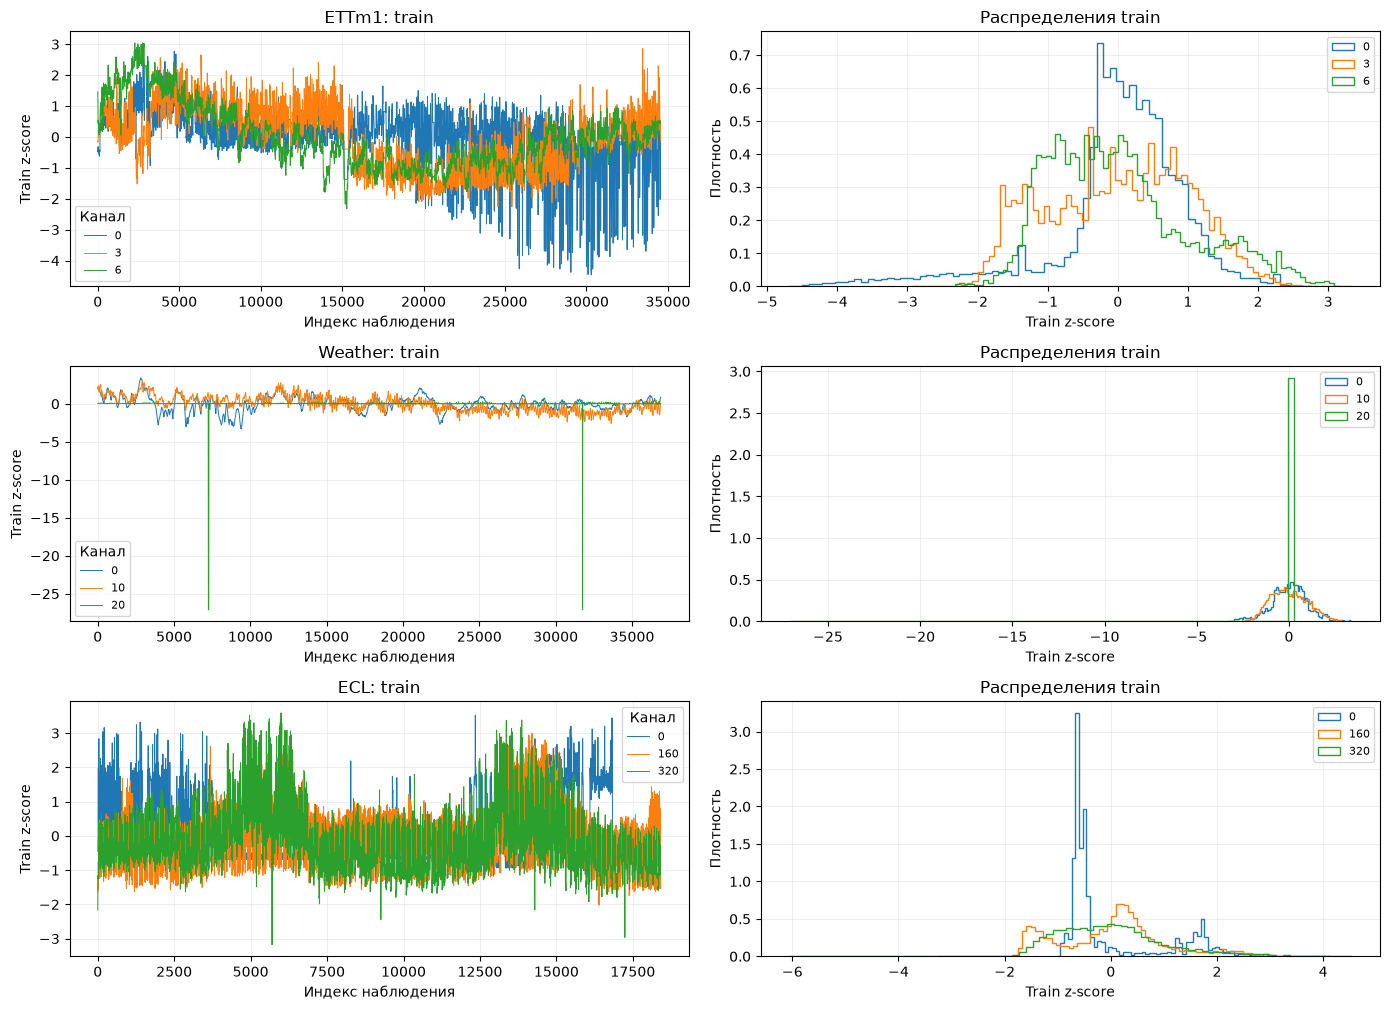

In [4]:
fig, axes = plt.subplots(len(catalog), 2, figsize=(14, 3.4*len(catalog)), squeeze=False)
for (name, item), (ax, hist) in zip(catalog.items(), axes):
    mean, scale = train_reference(item)
    train = item["raw"][:item["train_end"]]
    chosen = sorted(set([0, train.shape[1]//2, train.shape[1]-1]))
    step = max(1, len(train)//3000)
    for j in chosen:
        z = (train[:, j]-mean[j])/scale[j]
        ax.plot(np.arange(0, len(train), step), z[::step], lw=.7, label=item["channels"][j])
        hist.hist(z[np.isfinite(z)], bins=80, density=True, histtype="step",
                  label=item["channels"][j])
    ax.set(title=f"{name}: train", xlabel="Индекс наблюдения", ylabel="Train z-score")
    hist.set(title="Распределения train", xlabel="Train z-score", ylabel="Плотность")
    ax.legend(title="Канал", fontsize=8)
    hist.legend(fontsize=8)
save_plot(fig, "train_series_and_distributions.png")

## Сезонность и связи между каналами

ACF показывает линейную зависимость от прошлых значений. Сравниваем лаг 1,
суточный период из конфигурации и семь таких периодов. Высокая ACF может быть
связана также с трендом; она сама по себе не доказывает сезонность или прогнозируемость.
Корреляции каналов — одновременные Pearson на train, без причинной интерпретации.

In [5]:
correlation_rows = []
for name, item in catalog.items():
    train = item["raw"][:item["train_end"]]
    period = item["spec"]["seasonality"]
    acfs.append(autocorrelations(train, item["channels"], [1, period, 7*period]).assign(dataset=name))
    corr = pd.DataFrame(train).corr().to_numpy()
    pairs = np.abs(corr[np.triu_indices_from(corr, k=1)])
    pairs = pairs[np.isfinite(pairs)]
    correlation_rows.append(dict(dataset=name, channel_pairs=len(pairs),
                                 median_abs_correlation=np.median(pairs) if len(pairs) else np.nan,
                                 pct_abs_corr_above_08=100*np.mean(pairs > .8) if len(pairs) else np.nan))
acfs = save_table(pd.concat(acfs, ignore_index=True), "train_acf.csv")
display(acfs.groupby(["dataset", "lag"]).acf.agg(["median", "min", "max"]))
display(save_table(pd.DataFrame(correlation_rows), "train_channel_correlations.csv"))

median         min     max
dataset lag                             
ECL     1     0.9157  7.2863e-01  0.9921
        24    0.9314  1.8343e-01  0.9922
        168   0.9052  1.9284e-01  0.9712
ETTm1   1     0.9766  9.6426e-01  0.9984
        96    0.8108  3.1615e-01  0.9275
        672   0.7030  3.6134e-01  0.8398
Weather 1     0.9978  8.7399e-04  0.9999
        144   0.7864 -2.2139e-03  0.8813
        1008  0.6534 -1.0004e-05  0.7653

,dataset,channel_pairs,median_abs_correlation,pct_abs_corr_above_08
0,ETTm1,21,0.2395,9.5238
1,Weather,210,0.1463,10.4762
2,ECL,51360,0.4752,21.9840


## Изменение распределений после train

Сдвиг среднего измеряется в стандартных отклонениях train. Отношение стандартных
отклонений равно 1 при одинаковом масштабе. Для постоянного train-канала отношение
не определено. Сдвиг распределения описывает наблюдения, но не устанавливает его причину.

,,median_abs_mean_shift,max_abs_mean_shift,median_std_ratio
dataset,split,,,
ECL,validation,0.2326,2.0840,0.8746
ETTm1,validation,0.2356,0.5525,1.2396
Weather,validation,0.2157,0.6444,0.7254


,split,channel,mean_shift_train_std,std_ratio_to_train,outside_train_fence_pct,dataset,abs_mean_shift
409,validation,32,-2.0840,0.3485,0.0000,ECL,2.0840
434,validation,57,-1.8733,0.0193,0.0000,ECL,1.8733
622,validation,245,1.4618,1.1070,0.0000,ECL,1.4618
499,validation,122,-1.1596,0.4812,0.0000,ECL,1.1596
481,validation,104,-1.0095,0.3501,0.0000,ECL,1.0095
675,validation,298,1.0064,1.7726,1.7097,ECL,1.0064
508,validation,131,-0.9983,0.7848,0.1140,ECL,0.9983
493,validation,116,0.9165,0.4813,0.0000,ECL,0.9165
496,validation,119,-0.8786,0.5687,0.0380,ECL,0.8786
497,validation,120,-0.8156,0.7660,0.0380,ECL,0.8156


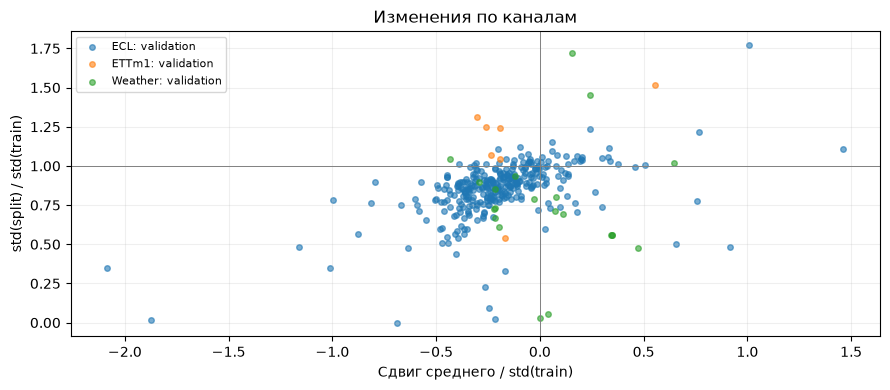

In [6]:
later = drifts[drifts.split != "train"].copy()
later["abs_mean_shift"] = later.mean_shift_train_std.abs()
display(later.groupby(["dataset", "split"]).agg(
    median_abs_mean_shift=("abs_mean_shift", "median"),
    max_abs_mean_shift=("abs_mean_shift", "max"),
    median_std_ratio=("std_ratio_to_train", "median")))
display(later.nlargest(12, "abs_mean_shift"))
fig, ax = plt.subplots(figsize=(9, 4))
for (name, split), group in later.groupby(["dataset", "split"]):
    ax.scatter(group.mean_shift_train_std, group.std_ratio_to_train, s=16, alpha=.6,
               label=f"{name}: {split}")
ax.axvline(0, color="gray", lw=.7)
ax.axhline(1, color="gray", lw=.7)
ax.set(xlabel="Сдвиг среднего / std(train)", ylabel="std(split) / std(train)",
       title="Изменения по каналам")
ax.legend(fontsize=8)
save_plot(fig, "split_drift.png")

## Прогнозные ориентиры на validation

Persistence повторяет последнее известное значение. Seasonal naive повторяет последний
известный суточный цикл, включая горизонты длиннее одного периода.
На каждом origin используются только предшествующие наблюдения; после продвижения
origin уже наблюдённая часть validation доступна как история.
Шаг между origin равен горизонту: целевые окна не перекрываются. Это отдельная оценка
на validation, **её числа нельзя напрямую сравнивать с test-метриками ноутбука результатов**.
Ошибки нормализованы по train; агрегирование даёт равный вес каналам и элементам прогноза.

In [7]:
for name, item in catalog.items():
    baseline_frames.append(naive_validation(item, config["horizons"]).assign(dataset=name))
baselines = save_table(pd.concat(baseline_frames, ignore_index=True), "validation_naive_by_channel.csv")
baseline_summary = baselines.groupby(["dataset", "horizon", "model"], as_index=False).agg(
    mse=("mse", "mean"), mae=("mae", "mean"), origins=("origins", "first"))
display(save_table(baseline_summary, "validation_naive_summary.csv"))

,dataset,horizon,model,mse,mae,origins
0,ECL,48,persistence,1.8355,1.0431,54
1,ECL,48,seasonal_naive,0.2588,0.2773,54
2,ECL,96,persistence,1.8481,1.0502,27
3,ECL,96,seasonal_naive,0.2952,0.3011,27
4,ETTm1,48,persistence,1.4566,0.7020,240
5,ETTm1,48,seasonal_naive,0.4973,0.4425,240
6,ETTm1,96,persistence,1.1963,0.6681,120
7,ETTm1,96,seasonal_naive,0.4973,0.4425,120
8,Weather,48,persistence,0.5839,0.3422,109
9,Weather,48,seasonal_naive,0.7457,0.3557,109


## Выводы по вычисленным данным

Ниже — описательные итоги, без проверки значимости и выбора модели по test.
Сезонность нужно проверять по отдельным каналам; медиана может скрывать различия.
Подробности ETTm1 находятся в `02_ettm1_analysis.ipynb`.

In [8]:
lines = []
for name, item in catalog.items():
    period = item["spec"]["seasonality"]
    daily = acfs[(acfs.dataset == name) & (acfs.lag == period)].acf.median()
    shift = later[(later.dataset == name) & (later.split == "validation")].abs_mean_shift.max()
    lines.append(f"- **{name}:** медианная ACF на периоде {period} = {daily:.3f}; "
                 f"максимальный сдвиг среднего validation = {shift:.3f} std(train).")
    for horizon, group in baseline_summary[baseline_summary.dataset == name].groupby("horizon"):
        best = group.loc[group.mse.idxmin()]
        lines.append(f"  H={horizon}: меньшая validation MSE у {best.model}: {best.mse:.4f}.")
summary_text = "\n".join(lines)
display(Markdown(summary_text))
(EXPORT / "findings.md").write_text(summary_text, encoding="utf-8")

- **ETTm1:** медианная ACF на периоде 96 = 0.811; максимальный сдвиг среднего validation = 0.553 std(train).
  H=48: меньшая validation MSE у seasonal_naive: 0.4973.
  H=96: меньшая validation MSE у seasonal_naive: 0.4973.
- **Weather:** медианная ACF на периоде 144 = 0.786; максимальный сдвиг среднего validation = 0.644 std(train).
  H=48: меньшая validation MSE у persistence: 0.5839.
  H=96: меньшая validation MSE у seasonal_naive: 0.7515.
- **ECL:** медианная ACF на периоде 24 = 0.931; максимальный сдвиг среднего validation = 2.084 std(train).
  H=48: меньшая validation MSE у seasonal_naive: 0.2588.
  H=96: меньшая validation MSE у seasonal_naive: 0.2952.

666